# Task 1 - Data Cleaning & Preprocessing
**Dataset:** E-commerce Customer Churn (`data_ecommerce_customer_churn.csv`)
**Goal:** Clean and prepare the dataset - handle missing values, encode categorical features, treat outliers, and standardize numerical features.

## Import Libraries and Load Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data_ecommerce_customer_churn.csv")
df.head()

,Tenure,WarehouseToHome,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,Churn
0,15.0,29.0,4,Laptop & Accessory,3,Single,2,0,7.0,143.32,0
1,7.0,25.0,4,Mobile,1,Married,2,0,7.0,129.29,0
2,27.0,13.0,3,Laptop & Accessory,1,Married,5,0,7.0,168.54,0
3,20.0,25.0,4,Fashion,3,Divorced,7,0,NaN,230.27,0
4,30.0,15.0,4,Others,4,Single,8,0,8.0,322.17,0


## Basic Exploration

In [2]:
print(f"Dataset has {df.shape[0]} rows and {df.shape[1]} columns")

Dataset has 3941 rows and 11 columns


In [3]:
print(df.dtypes)

Tenure                      float64
WarehouseToHome             float64
NumberOfDeviceRegistered      int64
PreferedOrderCat                str
SatisfactionScore             int64
MaritalStatus                   str
NumberOfAddress               int64
Complain                      int64
DaySinceLastOrder           float64
CashbackAmount              float64
Churn                         int64
dtype: object


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3941 entries, 0 to 3940
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Tenure                    3747 non-null   float64
 1   WarehouseToHome           3772 non-null   float64
 2   NumberOfDeviceRegistered  3941 non-null   int64  
 3   PreferedOrderCat          3941 non-null   str    
 4   SatisfactionScore         3941 non-null   int64  
 5   MaritalStatus             3941 non-null   str    
 6   NumberOfAddress           3941 non-null   int64  
 7   Complain                  3941 non-null   int64  
 8   DaySinceLastOrder         3728 non-null   float64
 9   CashbackAmount            3941 non-null   float64
 10  Churn                     3941 non-null   int64  
dtypes: float64(4), int64(5), str(2)
memory usage: 411.2 KB


In [5]:
print(df.isnull().sum())

Tenure                      194
WarehouseToHome             169
NumberOfDeviceRegistered      0
PreferedOrderCat              0
SatisfactionScore             0
MaritalStatus                 0
NumberOfAddress               0
Complain                      0
DaySinceLastOrder           213
CashbackAmount                0
Churn                         0
dtype: int64


In [6]:
df.describe()

,Tenure,WarehouseToHome,NumberOfDeviceRegistered,SatisfactionScore,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,Churn
count,3747.000000,3772.000000,3941.000000,3941.000000,3941.000000,3941.000000,3728.000000,3941.000000,3941.000000
mean,10.081398,15.650583,3.679269,3.088302,4.237757,0.282416,4.531652,176.707419,0.171023
std,8.498864,8.452301,1.013938,1.381832,2.626699,0.450232,3.667648,48.791784,0.376576
min,0.000000,5.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,9.000000,3.000000,2.000000,2.000000,0.000000,2.000000,145.700000,0.000000
50%,9.000000,14.000000,4.000000,3.000000,3.000000,0.000000,3.000000,163.340000,0.000000
75%,16.000000,21.000000,4.000000,4.000000,6.000000,1.000000,7.000000,195.250000,0.000000
max,61.000000,127.000000,6.000000,5.000000,22.000000,1.000000,46.000000,324.990000,1.000000


## Duplicate Check and Removal
There is no `CustomerID` or similar identifier column, so a duplicate here means a row matching on all 11 columns at once. `CashbackAmount` alone has thousands of distinct values down to the cent, so matching on every column including that one is not something that happens by chance - these are genuine duplicate records. Removing them now, before any statistics (imputation medians, encoding, scaling) are calculated from the data.

In [7]:
print("Duplicate rows before removal:", df.duplicated().sum())

Duplicate rows before removal: 671


In [8]:
rows_before = df.shape[0]

df = df.drop_duplicates().reset_index(drop=True)

rows_after = df.shape[0]

print(f"Rows before: {rows_before}")
print(f"Rows after: {rows_after}")
print(f"Duplicate rows removed: {rows_before - rows_after}")

Rows before: 3941
Rows after: 3270
Duplicate rows removed: 671


## Missing Value Analysis

In [9]:
missing = df.isnull().sum()
missing_percentage = (missing / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Values": missing,
    "Missing Percentage": missing_percentage
})

missing_summary[missing_summary["Missing Values"] > 0]

,Missing Values,Missing Percentage
Tenure,160,4.892966
WarehouseToHome,135,4.128440
DaySinceLastOrder,181,5.535168


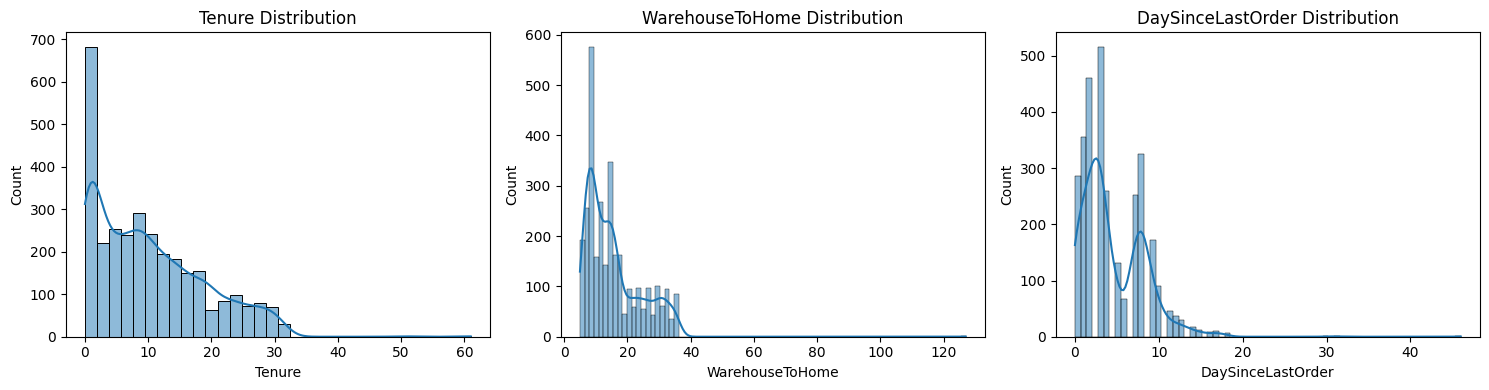

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(df["Tenure"].dropna(), kde=True, ax=axes[0])
axes[0].set_title("Tenure Distribution")

sns.histplot(df["WarehouseToHome"].dropna(), kde=True, ax=axes[1])
axes[1].set_title("WarehouseToHome Distribution")

sns.histplot(df["DaySinceLastOrder"].dropna(), kde=True, ax=axes[2])
axes[2].set_title("DaySinceLastOrder Distribution")

plt.tight_layout()
plt.show()

## Missing Value Handling
`Tenure`, `WarehouseToHome`, and `DaySinceLastOrder` are all right-skewed rather than symmetric, so the median is a better fill value than the mean here - the mean gets pulled toward the long tail, while the median stays representative of a typical row.

In [11]:
df["Tenure"] = df["Tenure"].fillna(df["Tenure"].median())
df["WarehouseToHome"] = df["WarehouseToHome"].fillna(df["WarehouseToHome"].median())
df["DaySinceLastOrder"] = df["DaySinceLastOrder"].fillna(df["DaySinceLastOrder"].median())

print("Missing values after imputation:")
print(df.isnull().sum())

Missing values after imputation:
Tenure                      0
WarehouseToHome             0
NumberOfDeviceRegistered    0
PreferedOrderCat            0
SatisfactionScore           0
MaritalStatus               0
NumberOfAddress             0
Complain                    0
DaySinceLastOrder           0
CashbackAmount              0
Churn                       0
dtype: int64


## Categorical Feature Inspection

In [12]:
print("PreferedOrderCat unique values:")
print(df["PreferedOrderCat"].unique())

print("\nMaritalStatus unique values:")
print(df["MaritalStatus"].unique())

PreferedOrderCat unique values:
<ArrowStringArray>
['Laptop & Accessory', 'Mobile', 'Fashion', 'Others', 'Mobile Phone',
 'Grocery']
Length: 6, dtype: str

MaritalStatus unique values:
<ArrowStringArray>
['Single', 'Married', 'Divorced']
Length: 3, dtype: str


`PreferedOrderCat` contains both `"Mobile"` and `"Mobile Phone"` as separate categories - these represent the same real category, just entered inconsistently. Merging them into a single `"Mobile"` category before encoding, otherwise one-hot encoding would create two different columns for what should be one category.

In [13]:
print("Value counts before merge:")
print(df["PreferedOrderCat"].value_counts())

df["PreferedOrderCat"] = df["PreferedOrderCat"].replace({"Mobile Phone": "Mobile"})

print("\nValue counts after merge:")
print(df["PreferedOrderCat"].value_counts())

Value counts before merge:
PreferedOrderCat
Laptop & Accessory    1213
Mobile Phone           725
Fashion                484
Mobile                 458
Grocery                241
Others                 149
Name: count, dtype: int64

Value counts after merge:
PreferedOrderCat
Laptop & Accessory    1213
Mobile                1183
Fashion                484
Grocery                241
Others                 149
Name: count, dtype: int64


## Categorical Encoding
Using one-hot encoding for both categorical columns. `drop_first=True` avoids redundant columns, and `dtype=int` keeps the new columns as 0/1 integers instead of booleans.

In [14]:
df = pd.get_dummies(
    df,
    columns=["PreferedOrderCat", "MaritalStatus"],
    drop_first=True,
    dtype=int
)

df.head()

,Tenure,WarehouseToHome,NumberOfDeviceRegistered,SatisfactionScore,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,Churn,PreferedOrderCat_Grocery,PreferedOrderCat_Laptop & Accessory,PreferedOrderCat_Mobile,PreferedOrderCat_Others,MaritalStatus_Married,MaritalStatus_Single
0,15.0,29.0,4,3,2,0,7.0,143.32,0,0,1,0,0,0,1
1,7.0,25.0,4,1,2,0,7.0,129.29,0,0,0,1,0,1,0
2,27.0,13.0,3,1,5,0,7.0,168.54,0,0,1,0,0,1,0
3,20.0,25.0,4,3,7,0,3.0,230.27,0,0,0,0,0,0,0
4,30.0,15.0,4,4,8,0,8.0,322.17,0,0,0,0,1,0,1


In [15]:
print("Shape after encoding:", df.shape)
print("\nColumns:", df.columns.tolist())

Shape after encoding: (3270, 15)

Columns: ['Tenure', 'WarehouseToHome', 'NumberOfDeviceRegistered', 'SatisfactionScore', 'NumberOfAddress', 'Complain', 'DaySinceLastOrder', 'CashbackAmount', 'Churn', 'PreferedOrderCat_Grocery', 'PreferedOrderCat_Laptop & Accessory', 'PreferedOrderCat_Mobile', 'PreferedOrderCat_Others', 'MaritalStatus_Married', 'MaritalStatus_Single']


## Numerical Feature Selection
These are the continuous/count numerical columns that will be standardized later. `Complain` and the one-hot encoded columns are already 0/1 flags and don't need scaling, and `Churn` is the target variable, so both are excluded here.

In [16]:
numeric_features = [
    "Tenure",
    "WarehouseToHome",
    "NumberOfDeviceRegistered",
    "SatisfactionScore",
    "NumberOfAddress",
    "DaySinceLastOrder",
    "CashbackAmount"
]

df[numeric_features].describe().T[["min", "max", "mean", "std"]]

,min,max,mean,std
Tenure,0.0,61.00,10.132110,8.440368
WarehouseToHome,5.0,127.00,15.406728,8.404449
NumberOfDeviceRegistered,1.0,6.00,3.676453,1.017390
SatisfactionScore,1.0,5.00,3.020795,1.395113
NumberOfAddress,1.0,22.00,4.222936,2.623195
DaySinceLastOrder,0.0,46.00,4.459939,3.609590
CashbackAmount,0.0,324.99,177.417670,49.310647


## Outlier Visualization
Boxplots are drawn on the original, unscaled values so the axis stays in real, interpretable units (days, addresses, cashback amount) instead of standard deviations.

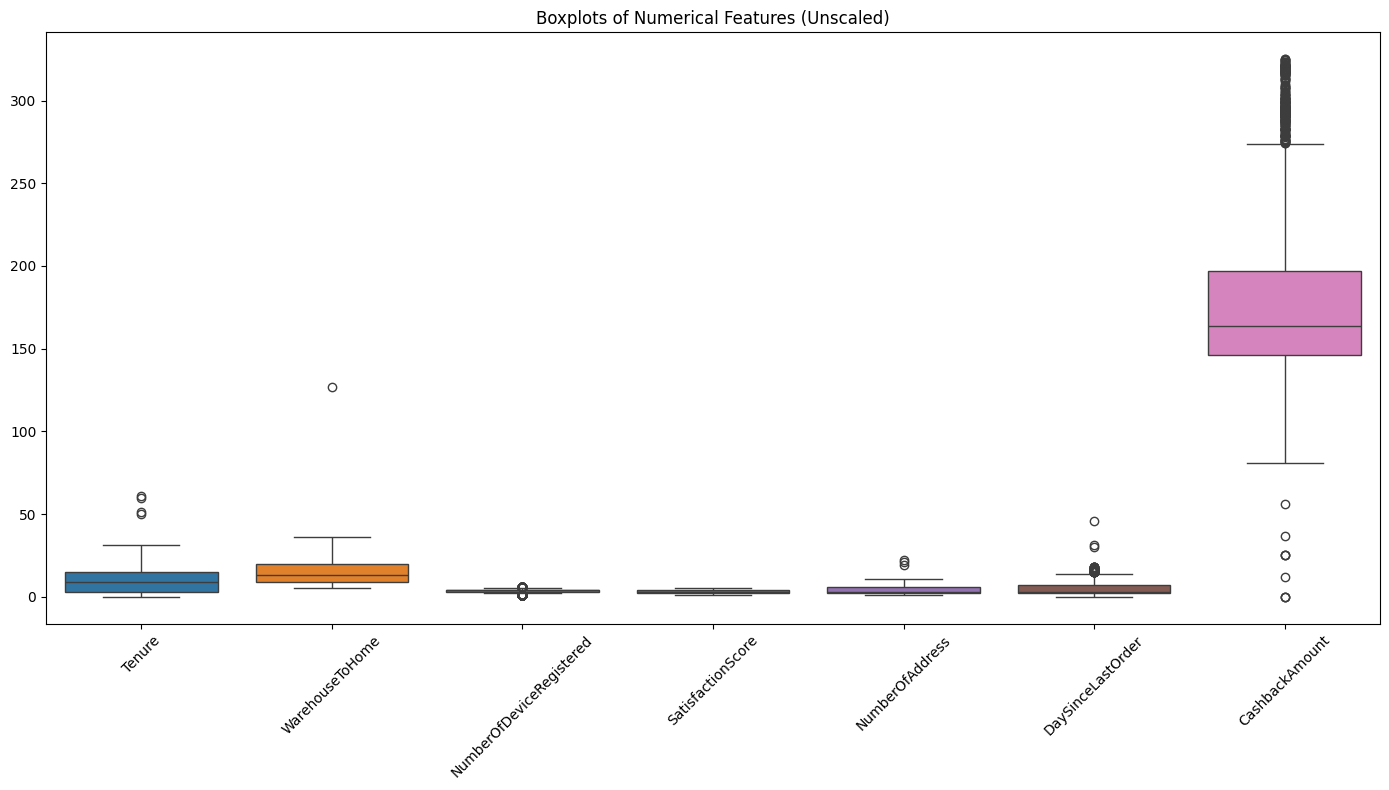

In [17]:
plt.figure(figsize=(14, 8))
sns.boxplot(data=df[numeric_features])
plt.title("Boxplots of Numerical Features (Unscaled)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## IQR Outlier Detection
Using the standard 1.5 x IQR rule to flag values outside the expected range for each numerical column.

In [18]:
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_counts = ((df[numeric_features] < lower_bound) |
                   (df[numeric_features] > upper_bound)).sum()

outlier_summary = pd.DataFrame({
    "Q1": Q1,
    "Q3": Q3,
    "IQR": IQR,
    "Lower Bound": lower_bound,
    "Upper Bound": upper_bound,
    "Outlier Count": outlier_counts
})

outlier_summary

,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count
Tenure,3.0000,15.0000,12.000,-15.000,33.000,4
WarehouseToHome,9.0000,20.0000,11.000,-7.500,36.500,1
NumberOfDeviceRegistered,3.0000,4.0000,1.000,1.500,5.500,226
SatisfactionScore,2.0000,4.0000,2.000,-1.000,7.000,0
NumberOfAddress,2.0000,6.0000,4.000,-4.000,12.000,3
DaySinceLastOrder,2.0000,7.0000,5.000,-5.500,14.500,40
CashbackAmount,145.8925,197.1375,51.245,69.025,274.005,253


Several columns show a non-zero outlier count, but a high count doesn't automatically mean the data is wrong. Checking the actual flagged values column by column before deciding anything.

In [19]:
device_outliers = df.loc[
    (df["NumberOfDeviceRegistered"] < lower_bound["NumberOfDeviceRegistered"]) |
    (df["NumberOfDeviceRegistered"] > upper_bound["NumberOfDeviceRegistered"]),
    "NumberOfDeviceRegistered"
]
print("NumberOfDeviceRegistered flagged values:")
print(device_outliers.value_counts().sort_index())

NumberOfDeviceRegistered flagged values:
NumberOfDeviceRegistered
1    137
6     89
Name: count, dtype: int64


`NumberOfDeviceRegistered` only ranges from 1 to 6. Because the range is so narrow, IQR flags the highest valid values (e.g. 6) even though they are completely normal device counts. Not an error - leaving these as they are.

In [20]:
tenure_outliers = df.loc[
    (df["Tenure"] < lower_bound["Tenure"]) |
    (df["Tenure"] > upper_bound["Tenure"]),
    "Tenure"
]
print("Tenure flagged values:")
print(tenure_outliers.sort_values())

Tenure flagged values:
3155    50.0
440     51.0
1150    60.0
51      61.0
Name: Tenure, dtype: float64


These go up to roughly 5 years of tenure - a plausible value for a long-standing customer. Not an error.

In [21]:
address_outliers = df.loc[
    (df["NumberOfAddress"] < lower_bound["NumberOfAddress"]) |
    (df["NumberOfAddress"] > upper_bound["NumberOfAddress"]),
    "NumberOfAddress"
]
print("NumberOfAddress flagged values:")
print(address_outliers.sort_values())

NumberOfAddress flagged values:
1466    19
2951    21
1900    22
Name: NumberOfAddress, dtype: int64


A small number of customers have more saved addresses than most - plausible for a heavy platform user. Not an error.

In [22]:
day_since_order_outliers = df.loc[
    (df["DaySinceLastOrder"] < lower_bound["DaySinceLastOrder"]) |
    (df["DaySinceLastOrder"] > upper_bound["DaySinceLastOrder"]),
    "DaySinceLastOrder"
]
print("DaySinceLastOrder flagged values:")
print(day_since_order_outliers.sort_values().unique())

DaySinceLastOrder flagged values:
[15. 16. 17. 18. 30. 31. 46.]


Just the higher end of a right-skewed distribution (customers who haven't ordered in a while) - realistic values, not errors.

In [23]:
cashback_outliers = df.loc[
    (df["CashbackAmount"] < lower_bound["CashbackAmount"]) |
    (df["CashbackAmount"] > upper_bound["CashbackAmount"]),
    "CashbackAmount"
]
print("CashbackAmount flagged values - min/max/count:")
print("Min:", cashback_outliers.min())
print("Max:", cashback_outliers.max())
print("Count:", cashback_outliers.count())

CashbackAmount flagged values - min/max/count:
Min: 0.0
Max: 324.99
Count: 253


A continuous, naturally right-skewed financial variable. The flagged values are still within a realistic cashback range - nothing here looks impossible.

In [24]:
warehouse_outliers = df.loc[
    (df["WarehouseToHome"] < lower_bound["WarehouseToHome"]) |
    (df["WarehouseToHome"] > upper_bound["WarehouseToHome"]),
    "WarehouseToHome"
]
print("WarehouseToHome flagged values:")
print(warehouse_outliers)

WarehouseToHome flagged values:
2384    127.0
Name: WarehouseToHome, dtype: float64


This one is different. Every other value in `WarehouseToHome` falls between 5 and 36, and one row jumps to **127** - far outside that range and disconnected from the rest of the distribution. This looks like a data entry error, not a real distance. This is the one genuine outlier being treated.

## Outlier Treatment
Removing only the row(s) where `WarehouseToHome` is beyond its IQR upper bound, using a condition rather than a hardcoded row index. The other flagged columns are left untouched since their values were checked above and found to be realistic.

In [25]:
rows_before_outlier_removal = df.shape[0]

df = df[
    ~((df["WarehouseToHome"] < lower_bound["WarehouseToHome"]) |
      (df["WarehouseToHome"] > upper_bound["WarehouseToHome"]))
].reset_index(drop=True)

rows_after_outlier_removal = df.shape[0]

print(f"Rows before: {rows_before_outlier_removal}")
print(f"Rows after: {rows_after_outlier_removal}")
print(f"Rows removed: {rows_before_outlier_removal - rows_after_outlier_removal}")

Rows before: 3270


Rows after: 3269
Rows removed: 1


## Duplicate Safety Check
Filling missing values with a shared median, and merging the `Mobile`/`Mobile Phone` category, can occasionally cause two rows that were originally different to become exact duplicates of each other. This is a side effect of the cleaning steps above, not leftover raw duplicates (those were already removed) - checking for it before finalizing the cleaned dataset.

In [26]:
rows_before_check = df.shape[0]

df = df.drop_duplicates().reset_index(drop=True)

rows_after_check = df.shape[0]

print(f"Rows before final duplicate check: {rows_before_check}")
print(f"Rows after final duplicate check: {rows_after_check}")
print(f"Rows removed: {rows_before_check - rows_after_check}")

Rows before final duplicate check: 3269
Rows after final duplicate check: 3267
Rows removed: 2


## Cleaned Dataset (Unscaled)
At this point duplicates are removed, missing values are filled, categories are cleaned and encoded, and the outlier is treated. This is the cleaned dataset in its original, meaningful units - saving it now, before scaling, since Task 2's EDA needs the numerical values to stay interpretable (e.g. actual days, actual cashback amount).

In [27]:
print("Cleaned (unscaled) dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

df.to_csv("cleaned_ecommerce_customer_churn.csv", index=False)
print("\nSaved cleaned_ecommerce_customer_churn.csv")

Cleaned (unscaled) dataset shape: (3267, 15)
Missing values: 0
Duplicate rows: 0



Saved cleaned_ecommerce_customer_churn.csv


## Standardization
Task 1 also requires the numerical features to be normalized/standardized. Scaling is applied to a separate copy of the cleaned data, so the unscaled version saved above stays intact and usable for Task 2's EDA. `Churn` (the target) and the 0/1 flag columns (`Complain`, and the one-hot encoded columns) are not scaled.

In [28]:
df_scaled = df.copy()

scaler = StandardScaler()
df_scaled[numeric_features] = scaler.fit_transform(df_scaled[numeric_features])

print("Standardized feature stats (mean should be ~0, std should be ~1):")
df_scaled[numeric_features].describe().T[["mean", "std", "min", "max"]]

Standardized feature stats (mean should be ~0, std should be ~1):


,mean,std,min,max
Tenure,4.567309e-17,1.000153,-1.200179,6.031706
WarehouseToHome,4.077954e-17,1.000153,-1.268495,2.522616
NumberOfDeviceRegistered,-1.631182e-17,1.000153,-2.630167,2.283348
SatisfactionScore,4.784800e-17,1.000153,-1.448846,1.418565
NumberOfAddress,1.315820e-16,1.000153,-1.228703,6.775251
DaySinceLastOrder,-7.394690e-17,1.000153,-1.236492,11.508531
CashbackAmount,-2.077038e-16,1.000153,-3.598496,2.992904


In [29]:
df_scaled.to_csv("cleaned_ecommerce_customer_churn_scaled.csv", index=False)
print("Saved cleaned_ecommerce_customer_churn_scaled.csv with shape", df_scaled.shape)

Saved cleaned_ecommerce_customer_churn_scaled.csv with shape (3267, 15)


## Final Validation

In [30]:
print("--- Cleaned (unscaled) dataset ---")
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Remaining categorical (object/string) columns:", df.select_dtypes(include=["object", "str"]).columns.tolist())
print()
print("--- Standardized dataset ---")
print("Shape:", df_scaled.shape)
print("Missing values:", df_scaled.isnull().sum().sum())
print("Duplicate rows:", df_scaled.duplicated().sum())
print("Numerical features standardized (mean ~0, std ~1):")
print(df_scaled[numeric_features].agg(["mean", "std"]).round(2))
print()
print("Churn unscaled in both versions (should show only 0/1):")
print("Cleaned dataset:", sorted(df["Churn"].unique()))
print("Scaled dataset:", sorted(df_scaled["Churn"].unique()))
print()
print("Data types (cleaned dataset):")
print(df.dtypes)

--- Cleaned (unscaled) dataset ---
Shape: (3267, 15)
Missing values: 0
Duplicate rows: 0
Remaining categorical (object/string) columns: []

--- Standardized dataset ---
Shape: (3267, 15)
Missing values: 0
Duplicate rows: 0
Numerical features standardized (mean ~0, std ~1):


      Tenure  WarehouseToHome  NumberOfDeviceRegistered  SatisfactionScore  \
mean     0.0              0.0                      -0.0                0.0   
std      1.0              1.0                       1.0                1.0   

      NumberOfAddress  DaySinceLastOrder  CashbackAmount  
mean              0.0               -0.0            -0.0  
std               1.0                1.0             1.0  

Churn unscaled in both versions (should show only 0/1):
Cleaned dataset: [np.int64(0), np.int64(1)]
Scaled dataset: [np.int64(0), np.int64(1)]

Data types (cleaned dataset):
Tenure                                 float64
WarehouseToHome                        float64
NumberOfDeviceRegistered                 int64
SatisfactionScore                        int64
NumberOfAddress                          int64
Complain                                 int64
DaySinceLastOrder                      float64
CashbackAmount                         float64
Churn                                

In [31]:
df.head()

,Tenure,WarehouseToHome,NumberOfDeviceRegistered,SatisfactionScore,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,Churn,PreferedOrderCat_Grocery,PreferedOrderCat_Laptop & Accessory,PreferedOrderCat_Mobile,PreferedOrderCat_Others,MaritalStatus_Married,MaritalStatus_Single
0,15.0,29.0,4,3,2,0,7.0,143.32,0,0,1,0,0,0,1
1,7.0,25.0,4,1,2,0,7.0,129.29,0,0,0,1,0,1,0
2,27.0,13.0,3,1,5,0,7.0,168.54,0,0,1,0,0,1,0
3,20.0,25.0,4,3,7,0,3.0,230.27,0,0,0,0,0,0,0
4,30.0,15.0,4,4,8,0,8.0,322.17,0,0,0,0,1,0,1
